In [1]:
import os
import os.path as op

import matplotlib.pyplot as plt
import pickle

import pandas as pd
from hnn_core.hnn_io import write_network_configuration, read_network_configuration
from hnn_core.dipole import average_dipoles
from hnn_core.dipole import _rmse, average_dipoles

import sys

pth = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning'
sys.path.append(pth)
#
sys.path.append(op.join(pth, 'utils'))
from general_plot_utils import assign_color
import hnn_core
from hnn_core.params import _short_name

from hnn_core import duecker_ET_model, simulate_dipole, read_dipole, MPIBackend, jones_2009_model

from hnn_core.optimization import Optimizer
import numpy as np
hnn_core_root = op.join(op.dirname(hnn_core.__file__))
pathfig = op.join(pth, 'new_model_HNN/figures')

# The number of cores may need modifying depending on your current machine.
n_procs = 10
cols = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
plt.rcParams['pdf.fonttype'] = 'truetype'
import matplotlib

col_lines = np.array(([27, 158, 119], [217,95,2], [117,112,179], [231,41,138], [102,166,30]))/255
cmap_lines = matplotlib.colors.ListedColormap(col_lines)
# Set global font sizes
plt.rcParams['font.size'] = 12          # Default text size
plt.rcParams['axes.titlesize'] = 12      # Title size
plt.rcParams['axes.labelsize'] = 12      # Axis labels (xlabel, ylabel)
plt.rcParams['xtick.labelsize'] = 12    # X-axis tick labels
plt.rcParams['ytick.labelsize'] = 12     # Y-axis tick labels
plt.rcParams['legend.fontsize'] = 12     # Legend text

cm_neurons = np.array([[218,166,156], [164,30,79], [119,161,187],[92,114,183]])/255

In [2]:
exp_dpl = read_dipole(op.join(pth, 'hnn-data/MEG_detection_data/S1_SupraT.txt'))

tstop = exp_dpl.times[-1]
scale_factor = 1000
smooth_window_len = 5

In [3]:
net = duecker_ET_model()
net.set_cell_positions(inplane_distance=30.)
depths = list(list(range(0,2000,100)))
electrode_pos = [(135, 135, dep) for dep in depths]
net.add_electrode_array('probe1', electrode_pos)
weights_ampa_p1 = {'L2_basket': 0.0025, 'L2_pyramidal': 0.15,
                   'L5_basket': 0.00015, 'L5_pyramidal': 0.0015}
weights_nmda_p1 = {'L2_basket': 0.0025, 'L2_pyramidal': 0.005,
                   'L5_basket': 0.00005, 'L5_pyramidal': .0005}
synaptic_delays_prox = {'L2_basket': 0.1, 'L2_pyramidal': .1,
                        'L5_basket': 1., 'L5_pyramidal': 1.}

net.add_evoked_drive('prox1', mu=18.5, sigma=4.5, numspikes=1, weights_ampa=weights_ampa_p1,
    weights_nmda=weights_nmda_p1, location='proximal', synaptic_delays=synaptic_delays_prox)

weights_ampa_d1 = {'L2_basket': 0.005, 'L2_pyramidal': 0.05, 'L5_pyramidal': 0.6}
weights_nmda_d1 = {'L2_basket': 0.0, 'L2_pyramidal': 0.015, 'L5_pyramidal': 0.5}
synaptic_delays_dist = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,'L5_pyramidal': 0.1}

net.add_evoked_drive('dist1', mu=55.5, sigma=6.5, numspikes=1, weights_ampa=weights_ampa_d1,
    weights_nmda=weights_nmda_d1, location='distal', synaptic_delays=synaptic_delays_dist)

weights_ampa_p2 = {'L2_basket': 0.05, 'L2_pyramidal': 0.75,
                   'L5_basket': 0.03, 'L5_pyramidal': 0.7}
weights_nmda_p2 = {'L2_basket': 0.01, 'L2_pyramidal': 0.1,
                   'L5_basket': 0.0003, 'L5_pyramidal': 0.2}

net.add_evoked_drive('prox2', mu=95, sigma=12, numspikes=2, weights_ampa=weights_ampa_p2,
    weights_nmda=weights_nmda_p2, location='proximal', synaptic_delays=synaptic_delays_prox)

#with MPIBackend(n_procs=n_procs):
dpl = simulate_dipole(net, tstop=tstop, n_trials=10,bsl_cor='duecker', record_ca='all', record_isec='all')



Joblib will run 10 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...
Building the NEURON model
[Done]
Trial 2: 0.03 ms...
Trial 2: 10.0 ms...
Trial 2: 20.0 ms...
Trial 2: 30.0 ms...
Trial 2: 40.0 ms...
Trial 2: 50.0 ms...
Trial 2: 60.0 ms...
Trial 2: 70.0 ms...
Trial 2: 80.0 ms...
Trial 2: 90.0 ms...
Trial 2: 100.0 ms...
Trial 2: 110.0 ms...
Trial 2: 120.0 ms...
Trial 2: 130.0 ms...
Trial 2: 140.0 ms...
Trial 2: 150.0 ms...
Trial 2: 160.0 ms...

In [4]:
dpl = [d.scale(scale_factor) for d in dpl]
dpl = [d.smooth(smooth_window_len) for d in dpl]


In [5]:
avg_dpl = average_dipoles(dpl)

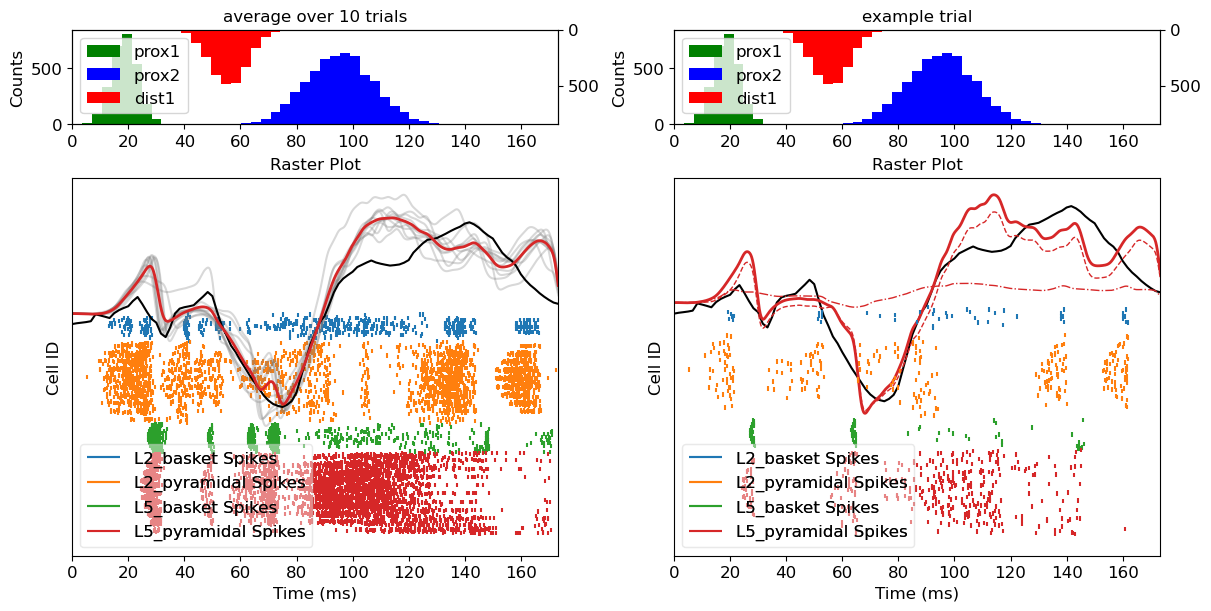

In [6]:
fig, ax = plt.subplots(2,2, figsize=(12,6), height_ratios=[0.25, 1], constrained_layout=True)

net.cell_response.plot_spikes_hist(ax=ax[0,0], show=False, invert_spike_types='dist1')
net.cell_response.plot_spikes_raster(ax=ax[1,0], show=False)
for d in dpl:
    ax[1,0].plot(d.times, d.data['agg'], color='gray', alpha=0.3)

ax[1,0].plot(exp_dpl.times, exp_dpl.data['agg'], color='k')

ax[1,0].plot(avg_dpl.times, avg_dpl.data['agg'], linewidth=2, color='C3')

net.cell_response.plot_spikes_hist(ax=ax[0,1], show=False, invert_spike_types='dist1')


ax[1,1].plot(exp_dpl.times, exp_dpl.data['agg'], color='k')

ax[1,1].plot(dpl[0].times, dpl[0].data['agg'], linewidth=2, color='C3', label='agg')
ax[1,1].plot(dpl[0].times, dpl[0].data['L5'], linewidth=1, color='C3', linestyle='--', label='L5')
ax[1,1].plot(dpl[0].times, dpl[0].data['L2'], linewidth=1, color='C3', linestyle='-.', label='L2')
ax[1,1].legend()

ax[0,0].set_title('average over 10 trials')
ax[0,1].set_title('example trial')

net.cell_response.plot_spikes_raster(ax=ax[1,1], trial_idx=0, show=False)

fig.savefig(f'{pathfig}/handtuned_ERP.png')

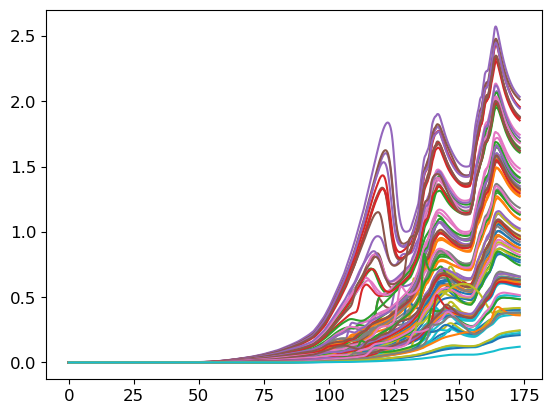

In [7]:
for i in np.arange(170, 270):
    plt.plot(net.cell_response.times, net.cell_response.isec[0][i]['apical_tuft']['apical_tuft_gabab'])



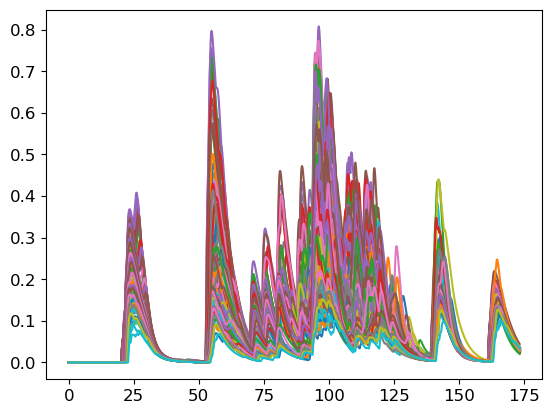

In [8]:
for i in np.arange(170, 270):
    plt.plot(net.cell_response.times, net.cell_response.isec[0][i]['apical_2']['apical_2_gabaa'])


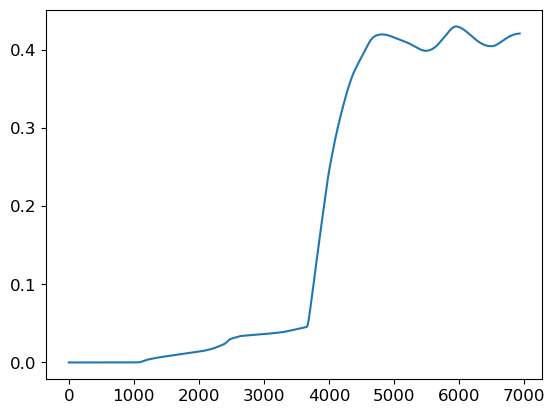

In [9]:
plt.plot(np.abs(np.array(net.cell_response.ca[0][200]['basal_3'])-5e-5)/5e-5)

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn-core/hnn_core/viz.py:1867: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


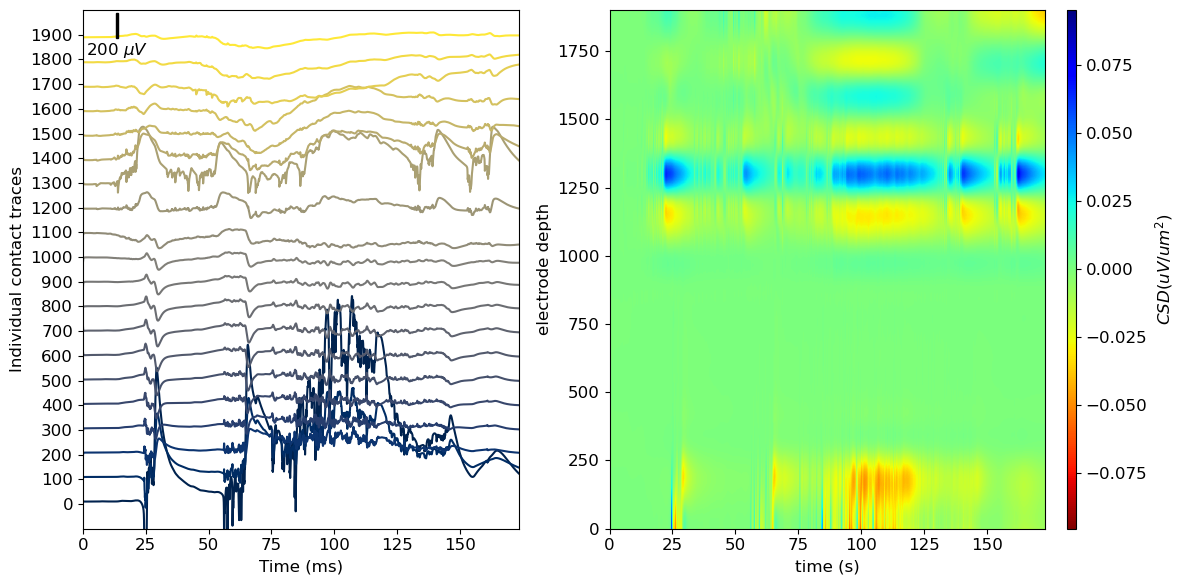

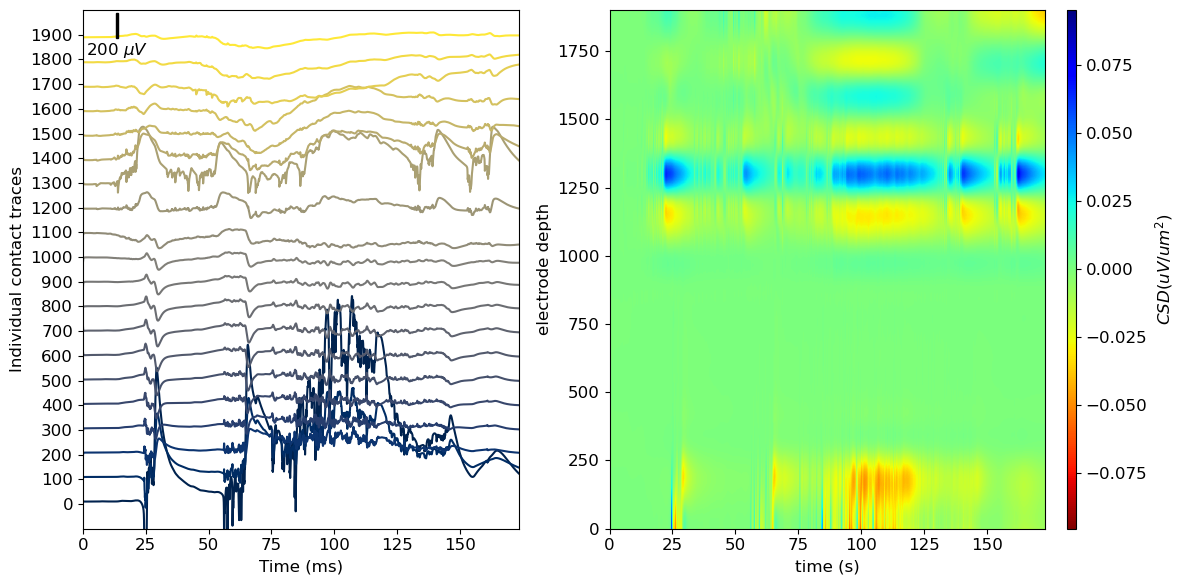

In [10]:
fig, axs = plt.subplots(1,2, figsize=(12,6), constrained_layout=True)
net.rec_arrays['probe1'][0].plot_lfp(ax=axs[0], show=False, voltage_offset=200)
net.rec_arrays['probe1'][0].plot_csd(ax=axs[1], show=False, sink='r')


In [11]:
lfp = net.rec_arrays['probe1'][0].voltages

In [12]:
from scipy import signal


sos = signal.butter(4, 300, 'lp', fs=dpl[0].sfreq, output='sos')
filtered = signal.sosfilt(sos, lfp)

In [13]:
filtered

array([[[ 0.00000000e+00,  1.14183977e-05,  9.90731958e-05, ...,
          2.78766676e+02,  2.78193756e+02,  2.77622049e+02],
        [ 0.00000000e+00,  7.49743799e-06,  6.37205151e-05, ...,
          1.07646147e+02,  1.07419773e+02,  1.07193913e+02],
        [ 0.00000000e+00, -9.30872941e-06, -7.73833122e-05, ...,
          1.74458404e+01,  1.74029997e+01,  1.73603319e+01],
        ...,
        [ 0.00000000e+00, -9.35203752e-06, -8.29042808e-05, ...,
          1.52809537e+02,  1.52920426e+02,  1.53030446e+02],
        [ 0.00000000e+00, -6.10416874e-06, -5.44820731e-05, ...,
          3.49418765e+01,  3.49890713e+01,  3.50362014e+01],
        [ 0.00000000e+00, -4.04917231e-06, -3.62541078e-05, ...,
         -5.70497048e+00, -5.70816271e+00, -5.71140259e+00]]],
      shape=(1, 20, 6934))

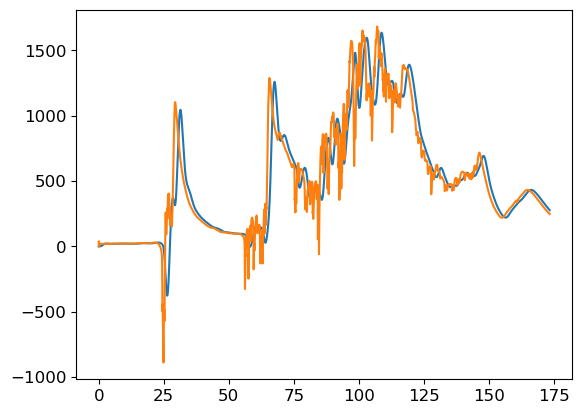

In [14]:
plt.plot(net.cell_response.times, filtered[0,0])
plt.plot(net.cell_response.times, lfp[0,0])
